# Range of application: grid of $(w_0, w_a)$ backgrounds, large $c_K$

Spectra computed with `scripts/compute_spectra.py` (`NAME = 'range_DE_grid'` with several `BACKGROUNDS`),
one file per background in `data/spectra/range_DE_grid/`.

In [1]:
%reload_ext autoreload
%autoreload 2

import numpy as np
import matplotlib.pyplot as plt

from hiclass_tools import load_spectra_group
from hiclass_tools.plotting import use_style, ColorScale

use_style(fontsize=15)

In [2]:
sets = load_spectra_group('range_DE_grid')    # {(w0, wa): SpectraSet}
k = next(iter(sets.values())).k
cK = np.unique(np.concatenate([s.cK for s in sets.values()]))   # union over backgrounds
cB = np.unique(np.concatenate([s.cB for s in sets.values()]))

print(f"{len(sets)} backgrounds: w0 in [{min(w0 for w0, _ in sets):.3g}, {max(w0 for w0, _ in sets):.3g}], "
      f"wa in [{min(wa for _, wa in sets):.3g}, {max(wa for _, wa in sets):.3g}]")
print(f"cK: {len(cK)} values in [{cK[0]:.3g}, {cK[-1]:.3g}]")
print(f"cB: {len(cB)} values in [{cB[0]:.3g}, {cB[-1]:.3g}]")
print(f"k:  {len(k)} values in [{k[0]:.3g}, {k[-1]:.3g}] h/Mpc")
print(f"Failed in CLASS: {sum(len(s.failed) for s in sets.values())}")

cb_colors = ColorScale(cB, 'Reds')
kJ_colors = ColorScale(cB, 'Greens')

25 backgrounds: w0 in [-1, -0.8], wa in [-1, 0]
cK: 10 values in [1e+03, 1e+06]
cB: 9 values in [0.611, 1.5]
k:  50 values in [0.001, 10] h/Mpc
Failed in CLASS: 40


In [3]:
# Sanity check of the characteristic scales
failed_checks = []
for (w0, wa), spectra in sets.items():
    for ck, cb in spectra.pk_mg:
        kB, kJ = spectra.scales(ck, cb)
        if not (np.isfinite(kB) and np.isfinite(kJ) and kB > 0 and kJ > 0):
            failed_checks.append((w0, wa, ck, cb, kB, kJ))

print(f"Pairs (ck, cb) evaluated: {sum(len(s.pk_mg) for s in sets.values())}")
print(f"Detected fails:           {len(failed_checks)}")

Pairs (ck, cb) evaluated: 2460
Detected fails:           0


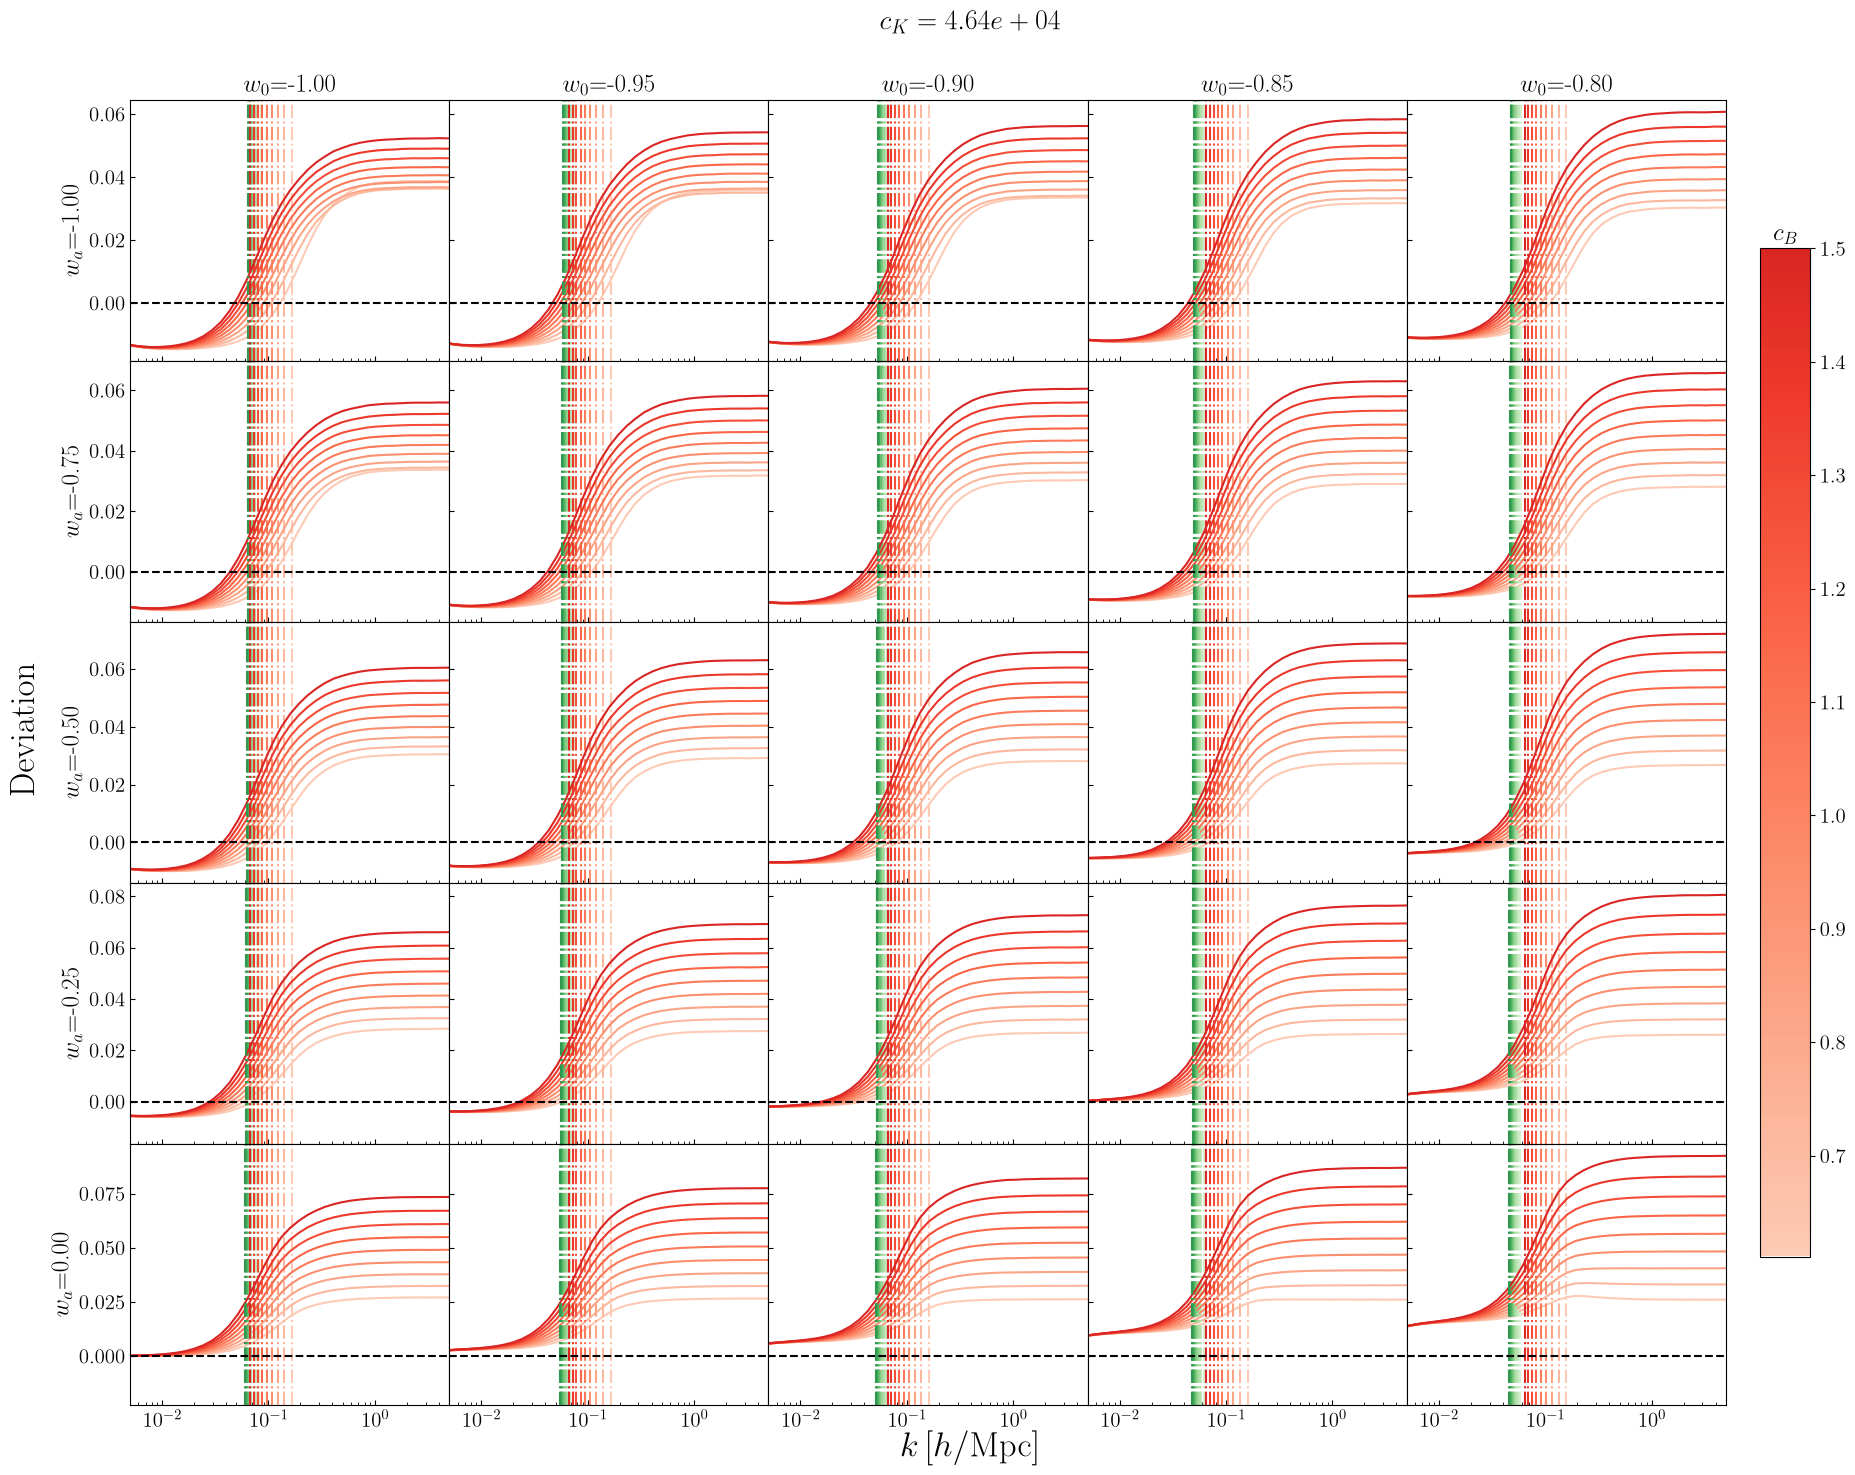

In [4]:
ck_fixed = cK[len(cK) // 2]
w0s = np.unique([w0 for w0, _ in sets])
was = np.unique([wa for _, wa in sets])[::-1]   # descending: wa = 0 on the top row

fig, axs = plt.subplots(len(was), len(w0s), figsize=(4*len(w0s), 3*len(was)), sharex=True, squeeze=False)
fig.subplots_adjust(left=0.08, right=0.92, bottom=0.05, top=0.92, hspace=0, wspace=0)
for row in axs:
    for ax in row[1:]:
        ax.sharey(row[0])
        ax.tick_params(axis='y', labelleft=False)

for (w0, wa), spectra in sets.items():
    ax = axs[list(was).index(wa), np.searchsorted(w0s, w0)]
    for cb in cB:
        if (ck_fixed, cb) not in spectra:
            continue
        ax.semilogx(k, spectra.deviation(ck_fixed, cb), color=cb_colors(cb))
        kB, kJ = spectra.scales(ck_fixed, cb)
        ax.axvline(x=kB, color=cb_colors(cb), linestyle='-.')
        ax.axvline(x=kJ, color=kJ_colors(cb), linestyle='-.')
    ax.axhline(y=0, color='k', linestyle='--')

axs[-1,-1].set_xlim([5e-3, 5])
for j, w0 in enumerate(w0s):
    axs[0,j].set_title(fr'$w_0$={w0:0.2f}', fontsize=18)
for i, wa in enumerate(was):
    axs[i,0].set_ylabel(fr'$w_a$={wa:0.2f}', fontsize=18)

fig.supxlabel(r"$k\,[h/\mathrm{Mpc}]$", fontsize=25)
fig.supylabel("Deviation", fontsize=25)
fig.suptitle(fr'$c_K = {ck_fixed:.3g}$', fontsize=20)

cbar = plt.colorbar(cb_colors.mappable, ax=axs, fraction=0.03, pad=0.02)
cbar.ax.set_title(r"$c_B$")

for ax in axs.flatten():
    ax.tick_params(axis='both', which='both', direction='in')